In [2]:
import tensorflow as ts
import matplotlib.pyplot as plt
import glob
import os
import cv2

In [3]:
train_images_Glioma = glob.glob('../data/Train/Glioma/images/*.jpg')
train_images_Meningioma = glob.glob('../data/Train/Meningioma/images/*.jpg')
train_images_No_Tumor = glob.glob('../data/Train/No_Tumor/images/*.jpg')
train_images_Pituitary = glob.glob('../data/Train/Pituitary/images/*.jpg')

train_labels_Glioma = glob.glob('../data/Train/Glioma/labels/*.txt')
train_labels_Meningioma = glob.glob('../data/Train/Meningioma/labels/*.txt')
train_labels_No_Tumor = glob.glob('../data/Train/No_Tumor/labels/*.txt')
train_labels_Pituitary = glob.glob('../data/Train/Pituitary/labels/*.txt')

val_images_Glioma = glob.glob('../data/Val/Glioma/images/*.jpg')
val_images_Meningioma = glob.glob('../data/Val/Meningioma/images/*.jpg')
val_images_No_Tumor = glob.glob('../data/Val/No_Tumor/images/*.jpg')
val_images_Pituitary = glob.glob('../data/Val/Pituitary/images/*.jpg')

val_labels_Glioma = glob.glob('../data/Val/Glioma/labels/*.txt')
val_labels_Meningioma = glob.glob('../data/Val/Meningioma/labels/*.txt')
val_labels_No_Tumor = glob.glob('../data/Val/No_Tumor/labels/*.txt')
val_labels_Pituitary = glob.glob('../data/Val/Pituitary/labels/*.txt')

In [5]:
def check_corrupted_images(images):
    corrupted = []

    for path in images:
        image = cv2.imread(path)

        if image is None:
            corrupted.append(path)

    print("Total images:", len(images))
    print("Corrupted images:", len(corrupted))

    return corrupted

check_corrupted_images(train_images_Glioma)
check_corrupted_images(train_images_Meningioma)
check_corrupted_images(train_images_No_Tumor)
check_corrupted_images(train_images_Pituitary)
print('')

Total images: 1153
Corrupted images: 0
Total images: 1449
Corrupted images: 0
Total images: 711
Corrupted images: 0
Total images: 1424
Corrupted images: 0



In [ ]:
# check if an img is exists in both classes 
# this is importent in classification
set_Glioma = set(train_images_Glioma)
set_Meningioma = set(train_images_Meningioma)
set_No_Tumor = set(train_images_No_Tumor)
set_Pituitary = set(train_images_Pituitary)


print(len(set_Glioma & set_Meningioma))
print(len(set_Glioma & set_No_Tumor))
print(len(set_Glioma & set_Pituitary))

print(len(set_Meningioma & set_No_Tumor))
print(len(set_Meningioma & set_Pituitary))

print(len(set_No_Tumor & set_Pituitary))
# nothing img exists in both categories

0
0
0
0
0
0


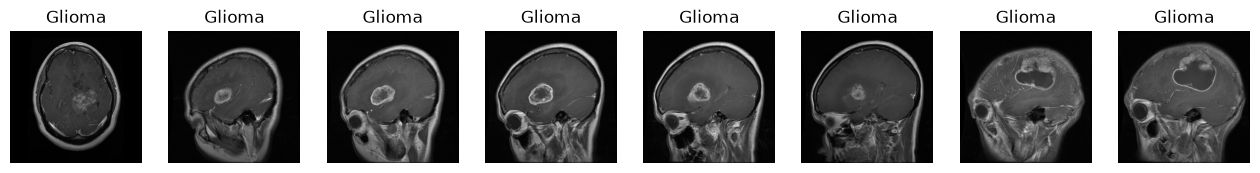

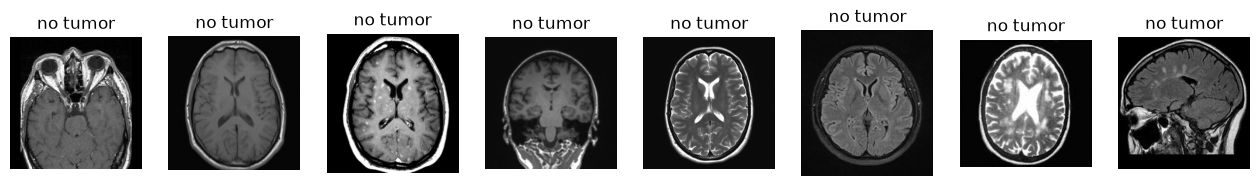

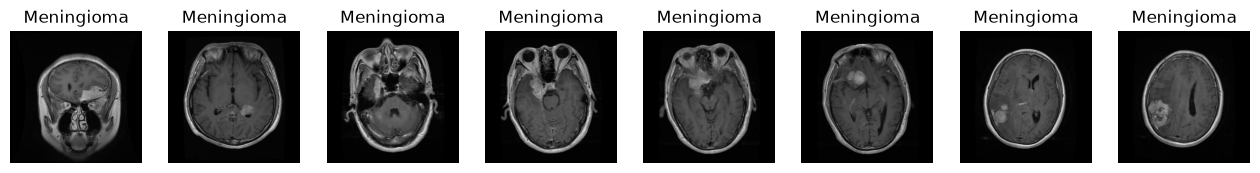

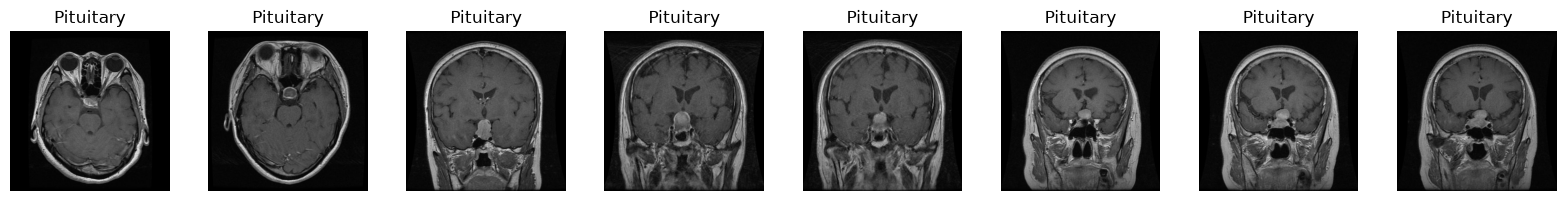

In [5]:

plt.figure(figsize=(16 , 2))
for i in range(8) :
    plt.subplot(1 , 8 , i+1)
    with open(train_labels_Glioma[i] , 'r') as f :
        soft_box = f.read().strip()
    img = plt.imread(train_images_Glioma[i])
    plt.title("Glioma")
    plt.imshow(img)
    plt.axis('off')
plt.show()

plt.figure(figsize=(16 , 2))
for i in range(8) :
    plt.subplot(1 , 8 , i+1)
    img = plt.imread(train_images_No_Tumor[i])
    plt.title("no tumor")
    plt.imshow(img)
    plt.axis('off')
plt.show()

plt.figure(figsize=(16 , 2))
for i in range(8) :
    plt.subplot(1 , 8 , i+1)
    img = plt.imread(train_images_Meningioma[i])
    plt.title("Meningioma")
    plt.imshow(img)
    plt.axis('off')
plt.show()

plt.figure(figsize=(16 , 2))
for i in range(8) :
    plt.subplot(1 , 8 , i+1)
    img = plt.imread(train_images_Pituitary[i])
    plt.title("Pituitary")
    plt.imshow(img)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [6]:
# check wether every image has it's own label
def check_images_labels(images, labels, name):
    image_names = {
        os.path.splitext(os.path.basename(path))[0]
        for path in images
    }

    label_names = {
        os.path.splitext(os.path.basename(path))[0]
        for path in labels
    }
    print("((" , name , ")) /Images:", len(image_names) , "/ Labels:", len(label_names) , "/ Images without labels:", len(image_names - label_names) , "/ Labels without images:", len(label_names - image_names) )


check_images_labels(
    train_images_Glioma,
    train_labels_Glioma,
    "Train - Glioma"
)

check_images_labels(
    train_images_Meningioma,
    train_labels_Meningioma,
    "Train - Meningioma"
)

check_images_labels(
    train_images_No_Tumor,
    train_labels_No_Tumor,
    "Train - No Tumor"
)

check_images_labels(
    train_images_Pituitary,
    train_labels_Pituitary,
    "Train - Pituitary"
)

# ckeck validation dataset
check_images_labels(
    val_images_Glioma,
    val_labels_Glioma,
    "Val - Glioma"
)

check_images_labels(
    val_images_Meningioma,
    val_labels_Meningioma,
    "Val - Meningioma"
)

check_images_labels(
    val_images_No_Tumor,
    val_labels_No_Tumor,
    "Val - No Tumor"
)

check_images_labels(
    val_images_Pituitary,
    val_labels_Pituitary,
    "Val - Pituitary"
)

(( Train - Glioma )) /Images: 1153 / Labels: 1153 / Images without labels: 0 / Labels without images: 0
(( Train - Meningioma )) /Images: 1449 / Labels: 1449 / Images without labels: 0 / Labels without images: 0
(( Train - No Tumor )) /Images: 711 / Labels: 711 / Images without labels: 0 / Labels without images: 0
(( Train - Pituitary )) /Images: 1424 / Labels: 1424 / Images without labels: 0 / Labels without images: 0
(( Val - Glioma )) /Images: 136 / Labels: 136 / Images without labels: 0 / Labels without images: 0
(( Val - Meningioma )) /Images: 140 / Labels: 140 / Images without labels: 0 / Labels without images: 0
(( Val - No Tumor )) /Images: 100 / Labels: 100 / Images without labels: 2 / Labels without images: 2
(( Val - Pituitary )) /Images: 136 / Labels: 136 / Images without labels: 0 / Labels without images: 0


In [7]:
# check the format of the label
with open(train_labels_Glioma[0] , "r") as f : print(f.read().split())
with open(train_labels_Meningioma[0] , "r") as f : print(f.read().split())
with open(train_labels_No_Tumor[0] , "r") as f : print(f.read().split())
with open(train_labels_Pituitary[0] , "r") as f : print(f.read().split())

['0', '0.567383', '0.519531', '0.189453', '0.148438']
['1', '0.619141', '0.471680', '0.191406', '0.115234']
['2', '0.502857', '0.675714', '0.851429', '0.648571']
['3', '0.507812', '0.441406', '0.093750', '0.050781']


In [8]:
import cv2
import matplotlib.pyplot as plt

def show_yolo_box(image_path, label_path):
    image = cv2.imread(image_path)

    if image is None:
        print("Could not read image:", image_path)
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        values = line.split()

        class_id = int(values[0])
        x_center, y_center, box_width, box_height = map(
            float, values[1:]
        )

        x_center *= width
        y_center *= height
        box_width *= width
        box_height *= height

        x1 = int(x_center - box_width / 2)
        y1 = int(y_center - box_height / 2)
        x2 = int(x_center + box_width / 2)
        y2 = int(y_center + box_height / 2)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

        cv2.putText(
            image,
            f"Class {class_id}",
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )
    return image

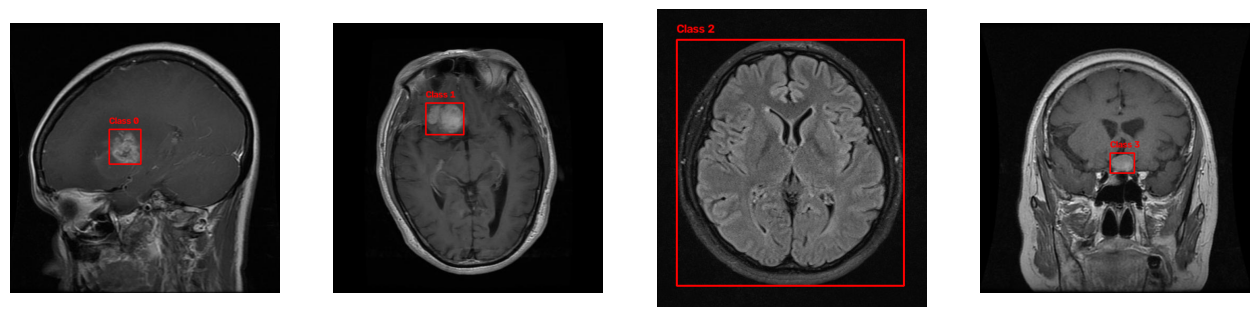

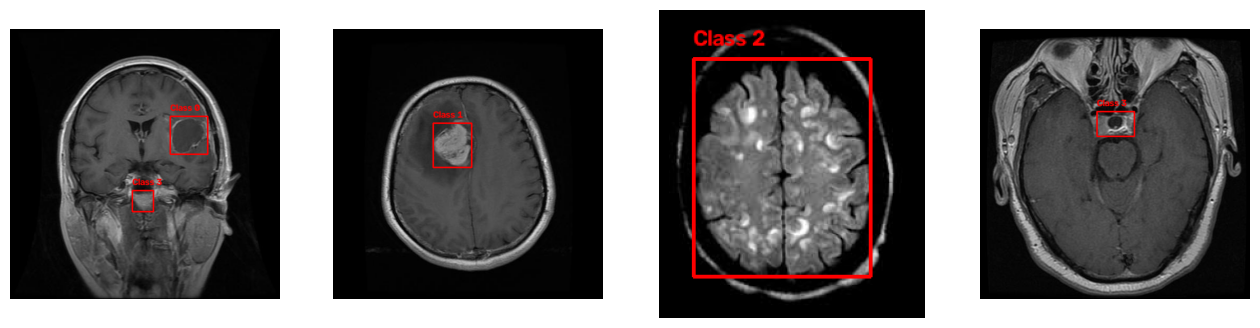

In [9]:
plt.figure(figsize=(16, 4))

img1 = show_yolo_box(train_images_Glioma[5],train_labels_Glioma[5])
img2 = show_yolo_box(train_images_Meningioma[5], train_labels_Meningioma[5])
img3 = show_yolo_box(train_images_No_Tumor[5], train_labels_No_Tumor[5])
img4 = show_yolo_box(train_images_Pituitary[5],train_labels_Pituitary[5])
imgs = [img1 , img2 , img3 , img4]
for i, img in enumerate(imgs) :
    plt.subplot(1 , 4 , i+1)
    plt.axis("off")
    plt.imshow(img)
plt.show()

# validation data
plt.figure(figsize=(16, 4))

img1 = show_yolo_box(val_images_Glioma[5],val_labels_Glioma[5])
img2 = show_yolo_box(val_images_Meningioma[5], val_labels_Meningioma[5])
img3 = show_yolo_box(val_images_No_Tumor[5], val_labels_No_Tumor[5])
img4 = show_yolo_box(val_images_Pituitary[5],val_labels_Pituitary[5])
imgs = [img1 , img2 , img3 , img4]

for i, img in enumerate(imgs) :
    plt.subplot(1 , 4 , i+1)
    plt.axis("off")
    plt.imshow(img)
plt.show()




In [10]:
train_classes = {
    "Glioma": train_images_Glioma,
    "Meningioma": train_images_Meningioma,
    "No Tumor": train_images_No_Tumor,
    "Pituitary": train_images_Pituitary
}

val_classes = {
    "Glioma": val_images_Glioma,
    "Meningioma": val_images_Meningioma,
    "No Tumor": val_images_No_Tumor,
    "Pituitary": val_images_Pituitary
}

for class_name, images in train_classes.items():
    print(f"{class_name}: {len(images)} images")
print('-'*20)
for class_name, images in val_classes.items():
    print(f"{class_name}: {len(images)} images")

Glioma: 1153 images
Meningioma: 1449 images
No Tumor: 711 images
Pituitary: 1424 images
--------------------
Glioma: 136 images
Meningioma: 140 images
No Tumor: 100 images
Pituitary: 136 images


In [11]:
def check_yolo_labels(labels):
    invalid = []

    for path in labels:
        with open(path, "r") as f:
            for line_number, line in enumerate(f, start=1):
                values = line.split()

                if len(values) != 5:
                    invalid.append((path, line_number, "Wrong number of values"))
                    continue

                try:
                    class_id = int(values[0])
                    x, y, w, h = map(float, values[1:])
                except ValueError:
                    invalid.append((path, line_number, "Non-numeric values"))
                    continue

                if class_id not in range(4):
                    invalid.append((path, line_number, "Invalid class ID"))
                    continue

                if not all(0 <= v <= 1 for v in (x, y, w, h)):
                    invalid.append((path, line_number, "Coordinates outside [0, 1]"))
                    continue

                if w <= 0 or h <= 0:
                    invalid.append((path, line_number, "Non-positive box dimensions"))
                    continue

                if (x - w / 2 < 0 or x + w / 2 > 1 or
                    y - h / 2 < 0 or y + h / 2 > 1):
                    invalid.append((path, line_number, "Box outside image boundaries"))

    print("Labels checked:", len(labels))
    print("Invalid annotations:", len(invalid))

    return invalid

all_train_labels = (
    train_labels_Glioma
    + train_labels_Meningioma
    + train_labels_No_Tumor
    + train_labels_Pituitary
)

invalid_labels = check_yolo_labels(all_train_labels)

Labels checked: 4737
Invalid annotations: 12


In [12]:
train_labels_Glioma_classes = [0] * len(train_images_Glioma)
train_labels_Meningioma_classes = [1] * len(train_images_Meningioma)
train_labels_No_Tumor_classes = [2] * len(train_images_No_Tumor)
train_labels_Pituitary_classes = [3] * len(train_images_Pituitary)

val_labels_Glioma_classes = [0] * len(val_images_Glioma)
val_labels_Meningioma_classes = [1] * len(val_images_Meningioma)
val_labels_No_Tumor_classes = [2] * len(val_images_No_Tumor)
val_labels_Pituitary_classes = [3] * len(val_images_Pituitary)

val_images = (val_images_Glioma +  val_images_Meningioma + val_images_No_Tumor + val_images_Pituitary)
val_labels = (val_labels_Glioma_classes + val_labels_Meningioma_classes + val_labels_No_Tumor_classes + val_labels_Pituitary_classes )

train_images = (train_images_Glioma +  train_images_Meningioma + train_images_No_Tumor + train_images_Pituitary)
train_labels = (train_labels_Glioma_classes + train_labels_Meningioma_classes + train_labels_No_Tumor_classes + train_labels_Pituitary_classes )

from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(train_images , train_labels ,  test_size=0.2 , random_state=100 , stratify=train_labels)

In [13]:
from collections import Counter

x_train_set = set(x_train)
x_test_set = set(x_test)
x_val_set = set(val_images)

print('-' * 40)
print("train in test : " , len(x_train_set & x_test_set))
print("train in val : " , len(x_train_set & x_val_set))
print("test in val : " , len(x_test_set & x_val_set))

print('-' * 40)
print("Training images:", len(x_train))
print("training labels : ",Counter(y_train))
print('-' * 40)
print("testing images:", len(x_test))
print("testing labels : ",Counter(y_test))
print('-' * 40)
print("validation images:", len(val_images))
print("validation labels : ",Counter(val_labels))
print('-' * 40)


----------------------------------------
train in test :  0
train in val :  0
test in val :  0
----------------------------------------
Training images: 3789
training labels :  Counter({1: 1159, 3: 1139, 0: 922, 2: 569})
----------------------------------------
testing images: 948
testing labels :  Counter({1: 290, 3: 285, 0: 231, 2: 142})
----------------------------------------
validation images: 512
validation labels :  Counter({1: 140, 0: 136, 3: 136, 2: 100})
----------------------------------------


In [14]:
import joblib

joblib.dump({
    "x_train": x_train,
    "y_train": y_train,
    "x_test": x_test,
    "y_test": y_test,
    "x_val": val_images,
    "y_val": val_labels
}, "../src/split.joblib")

['../src/split.joblib']